# Week 7 Notebook (back after a missed week)

I had some things going on and missed **Week 6 (Nov 2 to Nov 8)**, so there are **no Week 6 predictions** and nothing to grade for that week. I'm back this week.

This notebook does two things:
1. **Part 1: Week 7 predictions** (late start: Wednesday Nov 11 to Sunday Nov 15), same model (v1), committed before the games.
2. **Part 2: Week 5 recap**, grading the Week 5 predictions (Oct 28 to Nov 1), which I hadn't done yet.

I'll come back to this on the weekend to clean it up: write the analysis text, finish the recap, push the results files and update `SCOREBOARD.md`. The to-do list is at the bottom.

In [4]:
!rm -f data_pull.py data_pull.py.* scoring.py scoring.py.* stats.py stats.py.* matchup.py matchup.py.*
!wget -q -O data_pull.py https://raw.githubusercontent.com/avieno33/fantasy-hockey-weekly-predictions/main/src/data_pull.py
!wget -q -O scoring.py https://raw.githubusercontent.com/avieno33/fantasy-hockey-weekly-predictions/main/src/scoring.py
!wget -q -O stats.py https://raw.githubusercontent.com/avieno33/fantasy-hockey-weekly-predictions/main/src/stats.py
!wget -q -O matchup.py https://raw.githubusercontent.com/avieno33/fantasy-hockey-weekly-predictions/main/src/matchup.py

!mkdir -p predictions
!wget -q -O predictions/week01.csv https://raw.githubusercontent.com/avieno33/fantasy-hockey-weekly-predictions/main/predictions/week01.csv
!wget -q -O predictions/week02.csv https://raw.githubusercontent.com/avieno33/fantasy-hockey-weekly-predictions/main/predictions/week02.csv
!wget -q -O predictions/week03.csv https://raw.githubusercontent.com/avieno33/fantasy-hockey-weekly-predictions/main/predictions/week03.csv
!wget -q -O predictions/week04.csv https://raw.githubusercontent.com/avieno33/fantasy-hockey-weekly-predictions/main/predictions/week04.csv
!wget -q -O predictions/week05.csv https://raw.githubusercontent.com/avieno33/fantasy-hockey-weekly-predictions/main/predictions/week05.csv

from data_pull import get_player_id, get_game_log, get_games_in_window #type: ignore
from scoring import SKATER_FIELD_MAP, GOALIE_FIELD_MAP #type: ignore
from stats import get_player_estimates, get_prior_season_stats, _scored_game_log #type: ignore
from matchup import compare_players, compare_weekly #type: ignore

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [5]:
SEASON = "20262027"
PRIOR_SEASON = "20252026"

# Week 5 (being graded): late start, Wednesday Oct 28 to Sunday Nov 1
WEEK5 = {lg: ("2026-10-28", "2026-11-01") for lg in ("league_1", "league_2", "league_3")}

# Week 6 (Nov 2 to Nov 8) was missed: no predictions were made, so there is nothing to grade.

# Week 7 (being predicted): late start, Wednesday Nov 11 to Sunday Nov 15
WEEK7 = {lg: ("2026-11-11", "2026-11-15") for lg in ("league_1", "league_2", "league_3")}

league_scoring = {
    "league_1": {
        "skater": {"G": 2, "A": 1, "PIM": -0.25, "PPG": 0.5, "SHG": 2, "SHA": 1, "GWG": 1, "SOG": 0.1, "HIT": 0.25, "BLK": 0.25},
        "goalie": {"W": 5, "GA": -1, "SV": 0.1, "SHO": 5},
    },
    "league_2": {
        "skater": {"G": 2.5, "A": 1.5, "PIM": -0.25, "PPG": 0.5, "PPA": 0.25, "SHG": 1, "SHA": 0.5, "GWG": 1, "SOG": 0.1, "HIT": 0.4, "BLK": 0.5},
        "goalie": {"W": 5, "GA": -1, "SV": 0.15, "SHO": 5},
    },
    "league_3": {
        "skater": {"G": 2.55, "A": 2.37, "PPP": 1.77, "SHP": 1.73, "GWG": 3.0, "SOG": 0.1, "HIT": 0.2, "BLK": 0.15},
        "goalie": {"W": 3.85, "GA": -0.05, "SV": 0.03, "SHO": 5.75},
    },
}

SLEEPERS_W5 = ["Tye Kartye", "Tim Washe", "Maxim Shabanov"]   # graded in the Week 5 recap
SLEEPER_POSITION = {}   # all skaters

_id_cache = {}
def resolve_id(player):
    if isinstance(player, (int, np.integer)):
        return int(player)
    if player not in _id_cache:
        _id_cache[player] = get_player_id(player)
    return _id_cache[player]

def cfg_and_map(league, position):
    side = "goalie" if position == "G" else "skater"
    return league_scoring[league][side], (GOALIE_FIELD_MAP if position == "G" else SKATER_FIELD_MAP)

In [6]:
BLUE, ORANGE, GRAY, INK, MUTED, LIGHT = "#2a78d6", "#eb6834", "#a8a69f", "#0b0b0b", "#52514e", "#9cc3ee"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c2", "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10,
})

import time
_refreshed = set()

def window_stats(player, position, league, start, end):
    """Games and total fantasy points for one player in a date window, under one league's scoring."""
    pid = resolve_id(player)
    cfg, fmap = cfg_and_map(league, position)
    log = None
    for attempt in range(6):
        try:
            log = _scored_game_log(pid, SEASON, position, cfg, fmap, force_refresh=(pid not in _refreshed))
            _refreshed.add(pid)
            break
        except Exception as e:
            if "429" in str(e) and attempt < 5:
                time.sleep(10 * (attempt + 1))   # back off 10s, 20s, 30s...
                continue
            raise
    if log is None:
        return {"games": 0, "total": 0.0}
    d = log[(log["gameDate"] >= pd.Timestamp(start)) & (log["gameDate"] <= pd.Timestamp(end))]
    return {"games": len(d), "total": float(d["fantasy_points"].sum())}

def outcome(a, b):
    return 1.0 if a > b else (0.0 if a < b else 0.5)

from stats import build_full_skater_log  #type: ignore

def toi_minutes(value):
    try:
        m, s = str(value).split(":")
        return int(m) + int(s) / 60
    except Exception:
        return np.nan

def process_window(name, season, start=None, end=None):
    log = build_full_skater_log(resolve_id(name), season, include_hits_blocks=False)
    if log.empty:
        return None
    if start is not None:
        d = pd.to_datetime(log["gameDate"])
        log = log[(d >= pd.Timestamp(start)) & (d <= pd.Timestamp(end))]
    if log.empty:
        return None
    shots, goals = log["shots"].sum(), log["goals"].sum()
    return {"games": len(log), "pts_per_game": log["points"].mean(), "shots_per_game": log["shots"].mean(),
            "shooting_pct": goals / shots if shots else np.nan,
            "toi_per_game": log["toi"].map(toi_minutes).mean() if "toi" in log.columns else np.nan}

def goalie_process(name, season, start=None, end=None):
    log = get_game_log(resolve_id(name), season=season)
    if log.empty:
        return None
    if start is not None:
        d = pd.to_datetime(log["gameDate"])
        log = log[(d >= pd.Timestamp(start)) & (d <= pd.Timestamp(end))]
        if log.empty:
            return None
    def num(col):
        return pd.to_numeric(log[col], errors="coerce") if col in log.columns else pd.Series(np.nan, index=log.index)
    team = log["teamAbbrev"].iloc[-1] if "teamAbbrev" in log.columns else None
    team_games = len(get_games_in_window(team, start, end)) if (start is not None and team) else 82
    ga, sa, starts = num("goalsAgainst").sum(), num("shotsAgainst").sum(), num("gamesStarted").sum()
    return {"games": len(log), "starts": starts, "team_games": team_games,
            "start_share": starts / team_games if team_games else np.nan,
            "wins": int((log["decision"] == "W").sum()) if "decision" in log.columns else np.nan,
            "sv_pct": 1 - ga / sa if sa else np.nan, "ga_per_game": ga / len(log)}

# Part 1: Week 7 Predictions (Wed Nov 11 to Sun Nov 15)

Late start again, so most teams will have 2 to 3 games. Run this part first and commit `predictions/week07.csv` on its own before the first game. The Week 5 recap is further down and can wait.

In [9]:
# Pre-filled with last time's names. Overwrite the opponents (and any lineup changes) before running.
matchups_w7 = {
        "league_1": [
        {"position": "C", "me": "Connor McDavid", "opponent": "Auston Matthews"},
        {"position": "C", "me": "Tim Stutzle", "opponent": "Nico Hischier"},
        {"position": "LW", "me": "Filip Forsberg", "opponent": "Cutter Gauthier"},
        {"position": "LW", "me": "Kyle Connor", "opponent": "Easton Cowan"},
        {"position": "RW", "me": "Wyatt Johnston", "opponent": "Kiefer Sherwood"},
        {"position": "RW", "me": "Alex Tuch", "opponent": "Zach Hyman"},
        {"position": "D", "me": "Jakob Chychrun", "opponent": "Darren Raddysh"},
        {"position": "D", "me": "Mackenzie Weegar", "opponent": "Charlie McAvoy"},
        {"position": "D", "me": "Noah Dobson", "opponent": "Jake Sanderson"},
        {"position": "D", "me": "Mattias Samuelsson", "opponent": "None"},
        {"position": "UTIL", "me": "Seth Jarvis", "opponent": "Leo Carlsson"},
        {"position": "G", "me": "Jeremy Swayman", "opponent": "Andrei Vasilevskiy"},
        {"position": "G", "me": "Jake Oettinger", "opponent": "Darcy Kuemper"},
    ],
    "league_2": [
        {"position": "C", "me": "Nathan MacKinnon", "opponent": "Nick Suzuki"},
        {"position": "C", "me": "Sebastian Aho", "opponent": "Wyatt Johnston"},
        {"position": "LW", "me": "Filip Forsberg", "opponent": "Matthew Tkachuk"},
        {"position": "LW", "me": "Tim Stutzle", "opponent": "Alex Tuch"},
        {"position": "RW", "me": "Matt Boldy", "opponent": "Nikita Kucherov"},
        {"position": "RW", "me": "Drake Batherson", "opponent": "Logan Stankoven"},
        {"position": "D", "me": "Jakob Chychrun", "opponent": "Thomas Harley"},
        {"position": "D", "me": "Jackson LaCombe", "opponent": "Moritz Seider"},
        {"position": "D", "me": "Mattias Samuelsson", "opponent": "Shea Theodore"},
        {"position": "D", "me": "Charlie McAvoy", "opponent": "Brandt Clarke"},
        {"position": "UTIL", "me": "Sam Reinhart", "opponent": "Kirill Kaprizov"},
        {"position": "UTIL", "me": "Elias Pettersson", "opponent": "Jake Guentzel"},
        {"position": "G", "me": "Jake Oettinger", "opponent": "Igor Shesterkin"},
        {"position": "G", "me": "Mackenzie Blackwood", "opponent": "Lukas Dostal"},
    ],

    "league_3": [
        {"position": "C", "me": "Connor McDavid", "opponent": "Jack Hughes"},
        {"position": "C", "me": "Auston Matthews", "opponent": "Logan Cooley"},
        {"position": "C", "me": "Tim Stutzle", "opponent": "Charlie Coyle"},
        {"position": "LW", "me": "Kyle Connor", "opponent": "Jurai Slafkovsky"},
        {"position": "LW", "me": "Clayton Keller", "opponent": "Matthew Knies"},
        {"position": "LW", "me": "J.T. Miller", "opponent": "Will Smith"},
        {"position": "RW", "me": "Martin Necas", "opponent": "Beckett Sennecke"},
        {"position": "RW", "me": "Sam Reinhart", "opponent": "Trevor Zegras"},
        {"position": "RW", "me": "Will Cuylle", "opponent": "Brock Boeser"},
        {"position": "F", "me": "Alex Ovechkin", "opponent": "Ryan Lenard"},
        {"position": "F", "me": "Tom Wilson", "opponent": "Luke Evangelista"},
        {"position": "D", "me": "Jakob Chychrun", "opponent": "Luke Hughes"},
        {"position": "D", "me": "Mikhail Sergachev", "opponent": "Cole Hutson"},
        {"position": "D", "me": "Thomas Harley", "opponent": "Jackson Lacombe"},
        {"position": "D", "me": "Rasmus Andersson", "opponent": "Quinn Hughes"},
        {"position": "UTIL", "me": "Brock Nelson", "opponent": "Matthew Schaefer"},
        {"position": "G", "me": "Karel Vejmelka", "opponent": "Scott Wedgewood"},
        {"position": "G", "me": "Jakub Dobes", "opponent": "Stuart Skinner"},
    ],
}

In [10]:
# Only needed when the automatic team lookup gets someone wrong, name -> NHL team abbreviation
TEAM_OVERRIDES = {
    # "Some Player": "TOR",
}

# Only needed to override the automatic goalie start-share, name -> share of team games he starts (0 to 1)
GOALIE_START_SHARE = {
    # "Devon Levi": 0.6,
}

def current_team(player):
    """Most recent team from the game log, this season first, then last season. Returns (team, source)."""
    if player in TEAM_OVERRIDES:
        return TEAM_OVERRIDES[player], "override"
    pid = resolve_id(player)
    for season, source in ((SEASON, "this season"), (PRIOR_SEASON, "last season, VERIFY")):
        log = get_game_log(pid, season=season)
        if not log.empty and "teamAbbrev" in log.columns:
            return log.sort_values("gameDate").iloc[-1]["teamAbbrev"], source
    return None, "not found"

def goalie_start_share(player):
    """Share of his team's games a goalie starts, from last season's starts out of 82, unless overridden."""
    if player in GOALIE_START_SHARE:
        return GOALIE_START_SHARE[player]
    log = get_game_log(resolve_id(player), season=PRIOR_SEASON)
    if log.empty or len(log) < 20 or "gamesStarted" not in log.columns:
        return 0.5
    starts = pd.to_numeric(log["gamesStarted"], errors="coerce").fillna(0).sum()
    return float(min(max(starts / 82, 0.15), 0.95))

def is_placeholder(value):
    return isinstance(value, str) and (value.startswith("None") or "suspended" in value.lower())

def run_weekly_comparisons(league):
    start, end = WEEK7[league]
    results = []
    for m in matchups_w7[league]:
        pos = m["position"]
        base = {"week": 7, "league": league, "position": pos, "me": m["me"], "opponent": m["opponent"]}

        if is_placeholder(m["me"]) or is_placeholder(m["opponent"]):
            results.append({**base, "note": "no real comparison in this slot"})
            continue

        cfg, fmap = cfg_and_map(league, pos)
        me_id, opp_id = resolve_id(m["me"]), resolve_id(m["opponent"])
        me_est = get_player_estimates(me_id, pos, cfg, fmap, season=SEASON, prior_season=PRIOR_SEASON)
        opp_est = get_player_estimates(opp_id, pos, cfg, fmap, season=SEASON, prior_season=PRIOR_SEASON)
        if me_est is None or opp_est is None:
            results.append({**base, "note": f"skipped (no data: me={me_est is not None}, opp={opp_est is not None})"})
            continue

        me_team, me_src = current_team(m["me"])
        opp_team, opp_src = current_team(m["opponent"])
        if me_team is None or opp_team is None:
            results.append({**base, "note": "skipped (could not find a team, add a TEAM_OVERRIDES entry)"})
            continue

        me_games = len(get_games_in_window(me_team, start, end))
        opp_games = len(get_games_in_window(opp_team, start, end))
        me_share = goalie_start_share(m["me"]) if pos == "G" else 1.0
        opp_share = goalie_start_share(m["opponent"]) if pos == "G" else 1.0

        kwargs = dict(label_a=str(m["me"]), label_b=str(m["opponent"]), start_share_a=me_share, start_share_b=opp_share)
        weekly = compare_weekly(me_est, me_games, opp_est, opp_games, use="season", **kwargs)
        weekly_recent = compare_weekly(me_est, me_games, opp_est, opp_games, use="recent", **kwargs)
        per_game = compare_players(me_est, opp_est, str(m["me"]), str(m["opponent"]))

        p = weekly["probability_a_outperforms_b"]
        notes = []
        if "VERIFY" in me_src or "VERIFY" in opp_src:
            notes.append("team taken from last season, verify")
        if me_games == 0 or opp_games == 0:
            notes.append("a player has no games this week")
        results.append({
            **base,
            "me_team": me_team, "opp_team": opp_team,
            "me_games": me_games, "opp_games": opp_games,
            "me_start_share": me_share if pos == "G" else np.nan,
            "opp_start_share": opp_share if pos == "G" else np.nan,
            "me_week_mu": weekly["mu_a"], "opp_week_mu": weekly["mu_b"],
            "me_week_sigma": weekly["sigma_a"], "opp_week_sigma": weekly["sigma_b"],
            "p_me_outperforms": p,
            "confidence": max(p, 1 - p),
            "favored": "me" if p > 0.5 else ("opponent" if p < 0.5 else "even"),
            "p_per_game": per_game["probability_a_outperforms_b"],
            "p_recent_form": weekly_recent["probability_a_outperforms_b"],
            "me_games_so_far": me_est["games_played"], "opp_games_so_far": opp_est["games_played"],
            "low_confidence": bool(me_est["low_confidence"] or opp_est["low_confidence"]),
            "prediction_unit": "weekly_total",
            "model_version": "v1",
            "headline_pick": np.nan,
            "note": "; ".join(notes),
        })
    return pd.DataFrame(results)

active = [lg for lg, ms in matchups_w7.items() if ms]
print("Leagues with matchups:", active or "none yet, paste matchups above and re-run")
week7_results = {lg: run_weekly_comparisons(lg) for lg in active}

Leagues with matchups: ['league_1', 'league_2', 'league_3']
Loading game log for 8478402, 20262027 from cache, 0.3 hours old
Loading game log for 8478402, 20252026 from cache, 0.3 hours old
Loading game log for 8479318, 20262027 from cache, 0.3 hours old
Loading game log for 8479318, 20252026 from cache, 0.3 hours old
Loading game log for 8478402, 20262027 from cache, 0.3 hours old
Loading game log for 8479318, 20262027 from cache, 0.3 hours old
Loading game log for 8482116, 20262027 from cache, 0.3 hours old
Loading game log for 8482116, 20252026 from cache, 0.3 hours old
Loading game log for 8480002, 20262027 from cache, 0.3 hours old
Loading game log for 8480002, 20252026 from cache, 0.3 hours old
Loading game log for 8482116, 20262027 from cache, 0.3 hours old
Loading game log for 8480002, 20262027 from cache, 0.3 hours old
Loading game log for 8476887, 20262027 from cache, 0.3 hours old
Loading game log for 8476887, 20252026 from cache, 0.3 hours old
Loading game log for 8483445, 

In [11]:
all_w7 = pd.concat(week7_results.values(), ignore_index=True)
show = ["position", "me", "opponent", "me_games", "opp_games", "me_week_mu", "opp_week_mu",
        "p_me_outperforms", "p_per_game", "p_recent_form", "low_confidence", "note"]
for league, df in week7_results.items():
    print(f"\n=== {league.upper()} ===")
    d = df.copy()
    for c in ("p_me_outperforms", "p_per_game", "p_recent_form"):
        if c in d:
            d[c] = d[c].map(lambda p: f"{p:.1%}" if pd.notna(p) else "n/a")
    print(d[[c for c in show if c in d.columns]].to_string(index=False, float_format=lambda v: f"{v:.1f}"))

print()
for league, df in week7_results.items():
    d = df[df["p_me_outperforms"].notna()]
    if d.empty:
        continue
    print(f"{league}: favored in {int((d['favored'] == 'me').sum())} of {len(d)} comparable slots, "
          f"{d['p_me_outperforms'].mean():.1%} average win probability across slots")
    for r in d[(d["p_me_outperforms"] - 0.5).abs() < 0.02].itertuples():
        print(f"   coin flip: {r.me} vs {r.opponent} ({r.p_me_outperforms:.1%})")
    for r in d[d["me_games"] != d["opp_games"]].itertuples():
        print(f"   unequal games: {r.me} {r.me_games:.0f} vs {r.opponent} {r.opp_games:.0f}")
    for r in df[df["p_me_outperforms"].isna()].itertuples():
        print(f"   {r.me} vs {r.opponent}: {r.note}")


=== LEAGUE_1 ===
position                 me           opponent  me_games  opp_games  me_week_mu  opp_week_mu p_me_outperforms p_per_game p_recent_form low_confidence                            note
       C     Connor McDavid    Auston Matthews       3.0        2.0        10.7          5.2            86.7%      62.3%         89.9%          False                                
       C        Tim Stutzle      Nico Hischier       2.0        2.0         5.3          3.8            65.0%      60.7%         59.0%          False                                
      LW     Filip Forsberg    Cutter Gauthier       3.0        3.0         6.5          8.7            35.5%      41.5%         17.4%          False                                
      LW        Kyle Connor       Easton Cowan       2.0        2.0         4.9          2.8            72.0%      66.0%         72.5%          False                                
      RW     Wyatt Johnston    Kiefer Sherwood       3.0        3.0     

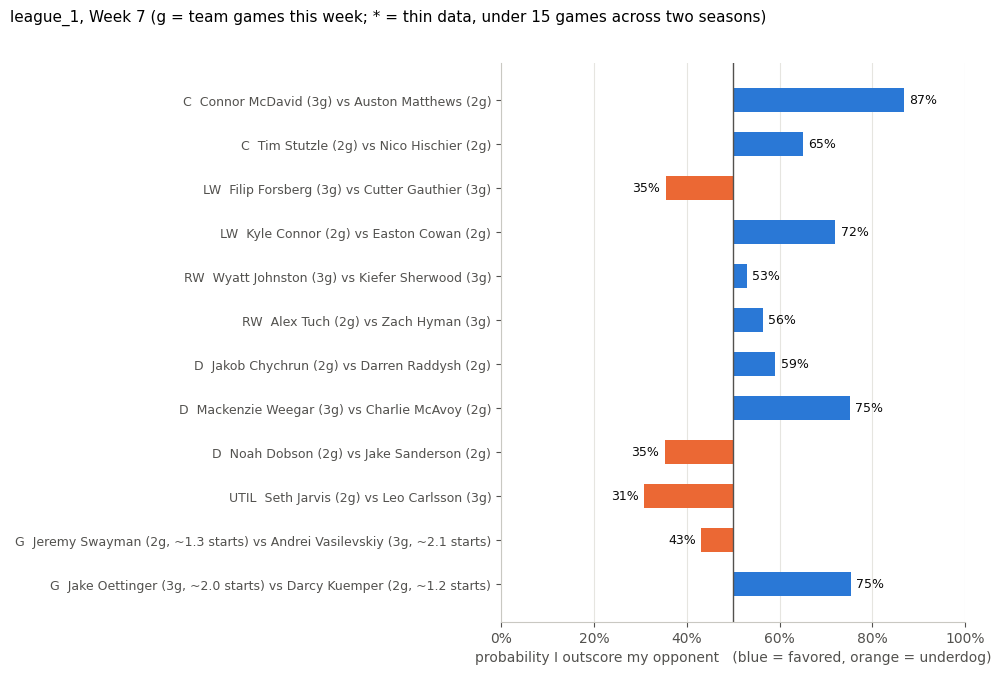

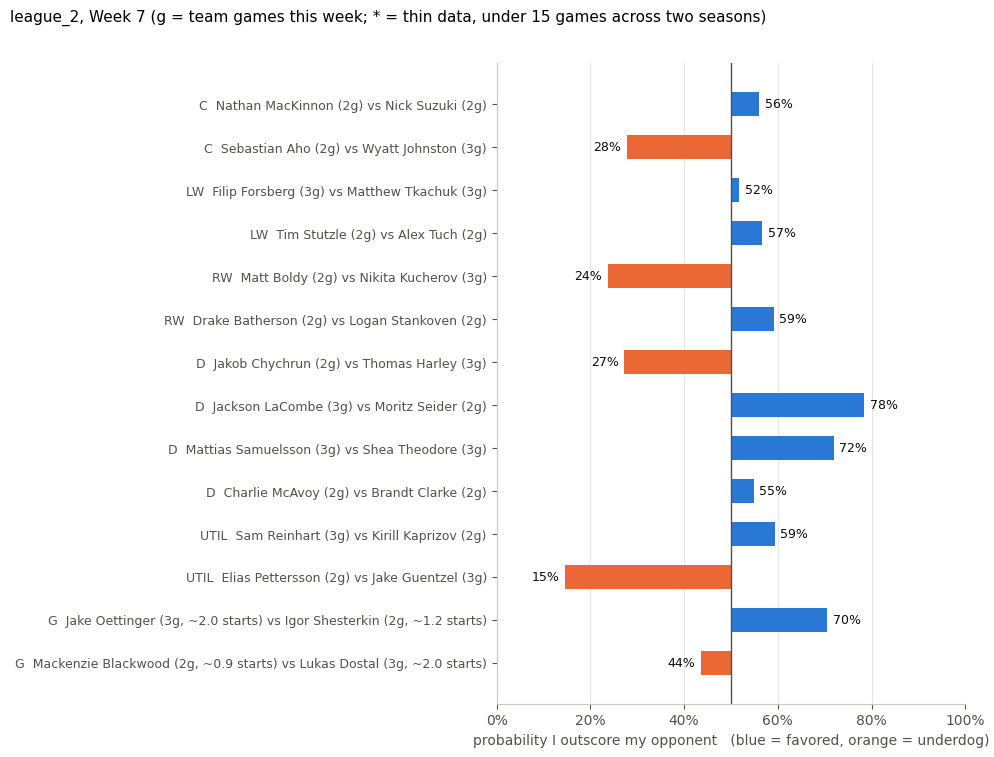

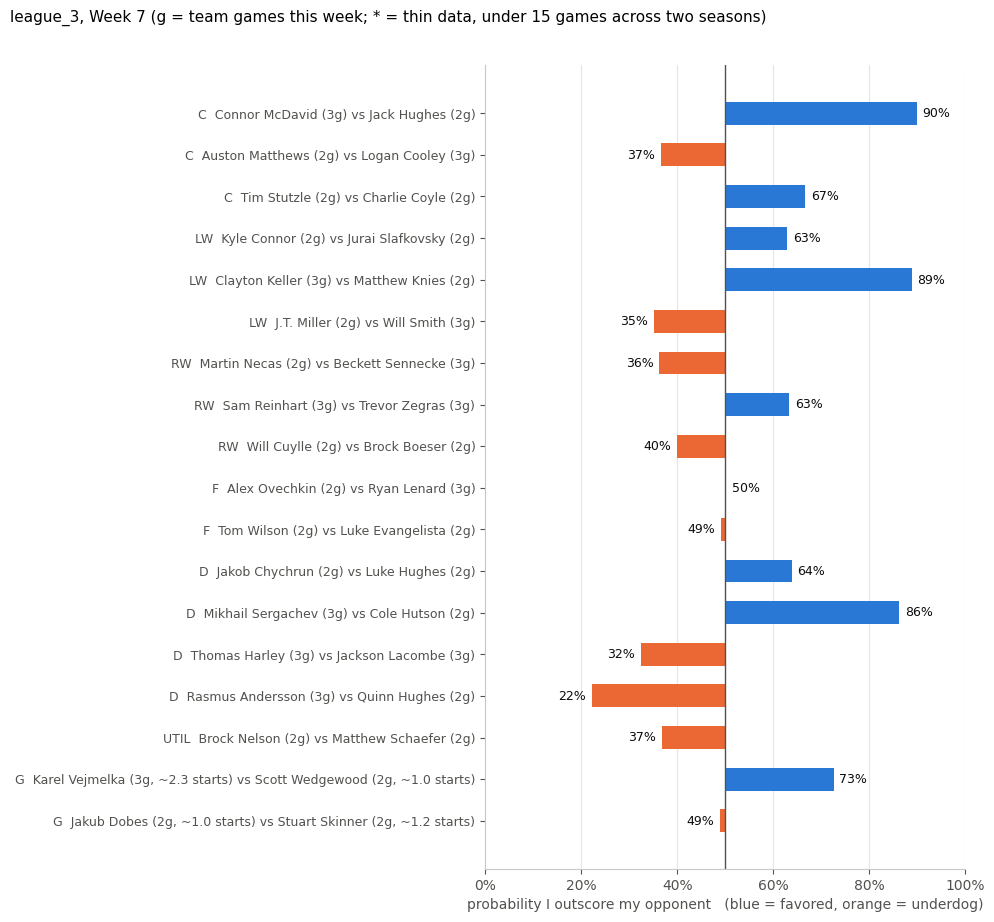

In [12]:
def plot_week7_bars(league, df):
    d = df[df["p_me_outperforms"].notna()].reset_index(drop=True)
    if d.empty:
        return
    y = np.arange(len(d))[::-1]
    colors = np.where(d["p_me_outperforms"] >= 0.5, BLUE, ORANGE)
    fig, ax = plt.subplots(figsize=(10, 0.42 * len(d) + 1.8))
    ax.barh(y, d["p_me_outperforms"] - 0.5, left=0.5, color=colors, height=0.55)
    ax.axvline(0.5, color=MUTED, linewidth=1)
    star = np.where(d["low_confidence"].astype(bool), " *", "")
    def side(name, games, share):
        # a goalie only starts some of his team's games, so show the expected starts too
        return f"{name} ({games:.0f}g)" if pd.isna(share) else f"{name} ({games:.0f}g, ~{games * share:.1f} starts)"
    labels = [f"{r.position}  {side(r.me, r.me_games, r.me_start_share)} vs {side(r.opponent, r.opp_games, r.opp_start_share)}{s}"
              for r, s in zip(d.itertuples(), star)]
    ax.set_yticks(y)
    ax.set_yticklabels(labels, fontsize=9)
    for yi, p in zip(y, d["p_me_outperforms"]):
        ax.text(p + (0.012 if p >= 0.5 else -0.012), yi, f"{p:.0%}", va="center",
                ha="left" if p >= 0.5 else "right", fontsize=9, color=INK)
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.set_xlabel("probability I outscore my opponent   (blue = favored, orange = underdog)")
    fig.suptitle(f"{league}, Week 7 (g = team games this week; * = thin data, under 15 games across two seasons)",
                 x=0.01, ha="left", fontsize=11)
    ax.grid(axis="y", visible=False)
    plt.tight_layout(rect=(0, 0, 1, 0.97))
    plt.show()

for league, df in week7_results.items():
    plot_week7_bars(league, df)

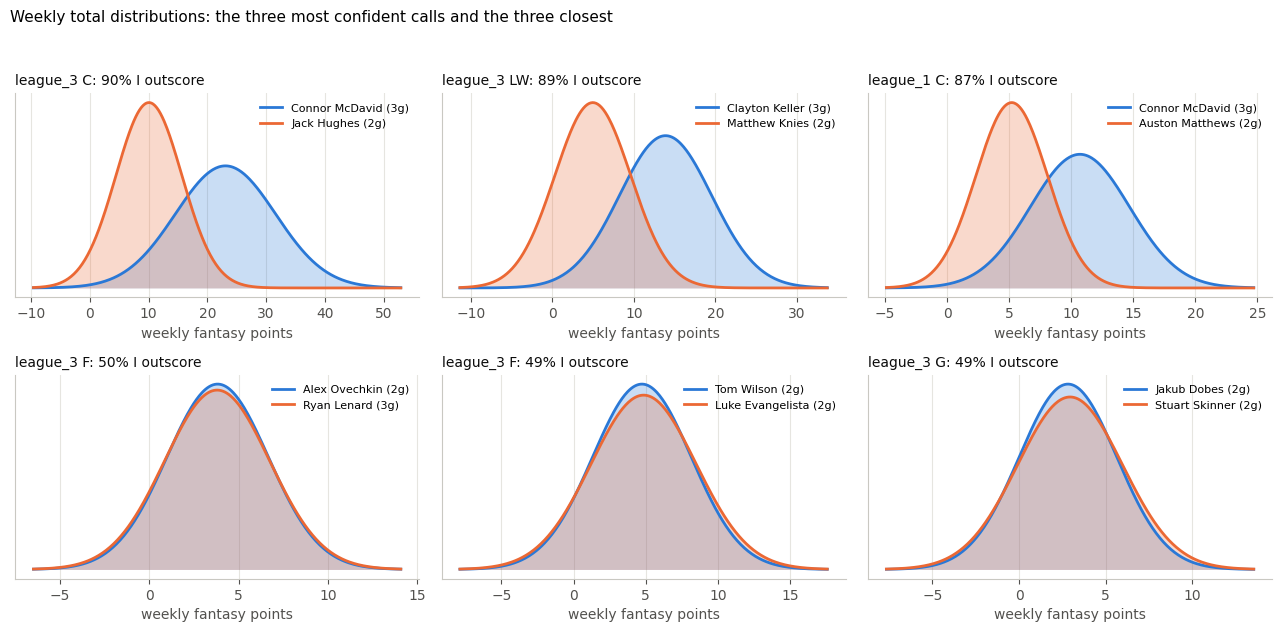

In [13]:
def plot_week7_distributions(all_df, n_each=3):
    ok = all_df[all_df["p_me_outperforms"].notna()]
    firm = ok.sort_values("confidence", ascending=False).head(n_each)
    close = ok.assign(gap=(ok["p_me_outperforms"] - 0.5).abs()).sort_values("gap").head(n_each)
    chosen = pd.concat([firm, close]).drop_duplicates(subset=["league", "me", "opponent"])
    n = len(chosen)
    cols = 3
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4.3 * cols, 3.2 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, (_, r) in zip(axes, chosen.iterrows()):
        lo = min(r["me_week_mu"] - 3.5 * r["me_week_sigma"], r["opp_week_mu"] - 3.5 * r["opp_week_sigma"])
        hi = max(r["me_week_mu"] + 3.5 * r["me_week_sigma"], r["opp_week_mu"] + 3.5 * r["opp_week_sigma"])
        x = np.linspace(max(lo, 0) if lo > -1 else lo, hi, 400)
        ax.fill_between(x, norm.pdf(x, r["me_week_mu"], r["me_week_sigma"]), color=BLUE, alpha=0.25, linewidth=0)
        ax.plot(x, norm.pdf(x, r["me_week_mu"], r["me_week_sigma"]), color=BLUE, linewidth=2, label=f"{r['me']} ({r['me_games']:.0f}g)")
        ax.fill_between(x, norm.pdf(x, r["opp_week_mu"], r["opp_week_sigma"]), color=ORANGE, alpha=0.25, linewidth=0)
        ax.plot(x, norm.pdf(x, r["opp_week_mu"], r["opp_week_sigma"]), color=ORANGE, linewidth=2, label=f"{r['opponent']} ({r['opp_games']:.0f}g)")
        ax.set_title(f"{r['league']} {r['position']}: {r['p_me_outperforms']:.0%} I outscore", loc="left", fontsize=10)
        ax.set_yticks([])
        ax.set_xlabel("weekly fantasy points")
        ax.legend(frameon=False, fontsize=8, loc="upper right")
        ax.grid(axis="y", visible=False)
    for ax in axes[n:]:
        ax.axis("off")
    fig.suptitle("Weekly total distributions: the three most confident calls and the three closest", x=0.01, ha="left", fontsize=11)
    plt.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()

plot_week7_distributions(all_w7)

In [18]:
g = all_w7[(all_w7["position"] == "G") & all_w7["p_me_outperforms"].notna()].copy()
g["me_exp_starts"] = g["me_games"] * g["me_start_share"]
g["opp_exp_starts"] = g["opp_games"] * g["opp_start_share"]
cols = ["league", "me", "opponent", "me_games", "me_start_share", "me_exp_starts",
        "opp_games", "opp_start_share", "opp_exp_starts",
        "me_week_mu", "opp_week_mu", "p_me_outperforms", "p_per_game"]
print(g[cols].to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print("\nstart_share = share of his team's games he's expected to start (last season's starts / 82 unless overridden)")
print("exp_starts = team games this week x start_share")

  league                  me           opponent  me_games  me_start_share  me_exp_starts  opp_games  opp_start_share  opp_exp_starts  me_week_mu  opp_week_mu  p_me_outperforms  p_per_game
league_1      Jeremy Swayman Andrei Vasilevskiy      2.00            0.66           1.32       3.00             0.71            2.12        4.79         6.17              0.43        0.55
league_1      Jake Oettinger      Darcy Kuemper      3.00            0.66           1.98       2.00             0.61            1.22        7.95         2.01              0.75        0.65
league_2      Jake Oettinger    Igor Shesterkin      3.00            0.66           1.98       2.00             0.62            1.24       10.01         5.07              0.70        0.57
league_2 Mackenzie Blackwood       Lukas Dostal      2.00            0.44           0.88       3.00             0.67            2.01        3.90         5.18              0.44        0.62
league_3      Karel Vejmelka    Scott Wedgewood      3.00   

**What stands out in Week 7:**

- **First call since Week 5.** I missed Week 6, so this is the first prediction set in two weeks. The model is still v1, unchanged, and the late-start window (Wed Nov 11 to Sun Nov 15) means everyone plays 2 or 3 games.
- **Game counts decide most of it.** Nearly every big gap comes from 3 games against 2. McDavid (3g vs 2g) is 87% against Matthews in League 1 and 90% against Hughes in League 3. Keller is 89% against Knies, Sergachev 86% against Hutson, and LaCombe 78% against Seider. The biggest underdogs are mostly the reverse: Pettersson (2g) is 15% against Guentzel (3g), Andersson 22%, Boldy 24%, Chychrun in League 2 27%, and Aho 28%.
- **Three coin flips in League 3.** Ovechkin vs Lenard (50%), Wilson vs Evangelista (49%) and Dobes vs Skinner (49%) have almost identical distributions. The model has no real edge there.
- **Goalies are the least certain.** Oettinger is 75% in League 1 and 70% in League 2 on about 2.0 expected starts, and Vejmelka is 73% on about 2.3. The weakest case is Blackwood at about 0.9 expected starts (44%). Start share is an estimate from last season, so any goalie call can swing on one backup start.
- **The leagues overlap.** Stutzle is in all three leagues, Chychrun in all three (59%, 27%, 64%), McDavid in two, and Oettinger in two. If one of them has a big week, it counts three times, so the effective sample is smaller than the 44 matchups suggest. For the same reason I'm counting each player once in the headline picks.
- **Roughly 25 favoured, 18 underdog, 1 coin flip.** The model leans toward my side overall, but the strongest calls sit in League 3 and in the star-vs-star matchup in League 1.
- **What I'm watching.** In Weeks 2 to 4 the 80%+ calls hit less often than the model said. This week has five of them (McDavid twice, Keller, Sergachev and Oettinger-adjacent goalie calls near 75%), so I'm tracking that bucket again.

In [19]:
HEADLINE_PICKS = [
    ("league_1", "Connor McDavid", "Auston Matthews"),
    ("league_2", "Jackson LaCombe", "Moritz Seider"),
    ("league_3", "Clayton Keller", "Matthew Knies"),
]
assert len(HEADLINE_PICKS) == 3, "pick exactly three headline calls"

import os
out = pd.concat(week7_results.values(), ignore_index=True)
out["headline_pick"] = False
for lg, me, opp in HEADLINE_PICKS:
    mask = (out["league"] == lg) & (out["me"] == me) & (out["opponent"] == opp)
    assert mask.sum() == 1, f"headline pick not found: {lg} {me} vs {opp}"
    out.loc[mask, "headline_pick"] = True
out["window_start"], out["window_end"] = WEEK7["league_1"]
out["late_start"] = WEEK7["league_1"][0] != "2026-11-09"   # True unless the window starts on the Monday
out["source"] = "model_v1"
os.makedirs("predictions", exist_ok=True)
out.to_csv("predictions/week07.csv", index=False)
print(out.shape, out["headline_pick"].sum(), "headline picks")
try:
    from google.colab import files  # type: ignore
    files.download("predictions/week07.csv")
except ImportError:
    pass

(45, 31) 3 headline picks


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Week 7 sleepers

(Pick three low-rostered players before the games, fill in the names below, then write a one-line thesis for each.)

In [23]:
SEASON_START = "2026-09-01"
TODAY = (pd.Timestamp(WEEK7["league_1"][0]) - pd.Timedelta(days=1)).strftime("%Y-%m-%d")   # "this season so far", through the day before the window

In [24]:
SLEEPERS_W7 = ["Noah Ostlund", "Matvei Gridin", "Emmitt Finnie"]
ROSTERED_W7 = {"Noah Ostlund": 7, "Matvei Gridin": 17, "Emmitt Finnie": 16}   # % rostered, check Yahoo
SLEEPER_POSITION_W7 = {}

SLEEPER_THESIS_W7 = {
    "Noah Ostlund": (
        "Role, not luck. He plays over 19 minutes a night on BUF's lead power play and second line, "
        "and has 37 shots, 3 power-play points and 9 points in the games so far. The shot volume and "
        "power-play time should hold up even if the scoring cools. He is rostered in only about 7% of "
        "leagues, and BUF plays N games in my Wed to Sun window."
    ),
    "Matvei Gridin": (
        "Power play driven. He has 9 of his 10 points and 24 shots in the last 10 games, with 5 "
        "power-play points in 16+ minutes on CGY's first unit. He is only on the third line at even "
        "strength, so the bet is the power play and the shots, not the line. Rostered in about 17% "
        "of leagues, and CGY plays N games in my window."
    ),
    "Emmitt Finnie": (
        "Opportunity change. He moved onto DET's first line and first power play after Larkin left "
        "the lineup, which should mean more minutes and more shots. He has only a short run in the "
        "new role, so this is the least proven of the three. Rostered in about 16% of leagues as of "
        "Week 6, and DET plays N games in my window."
    ),
}

In [25]:
rows = []
for name in SLEEPERS_W7:
    pos = SLEEPER_POSITION_W7.get(name, "F")
    pid = resolve_id(name)
    team, src = current_team(name)
    team_games = len(get_games_in_window(team, *WEEK7["league_1"])) if team else np.nan
    share = goalie_start_share(name) if pos == "G" else np.nan
    for league in ("league_1", "league_2", "league_3"):
        cfg, fmap = cfg_and_map(league, pos)
        now = window_stats(name, pos, league, SEASON_START, TODAY)
        avg = now["total"] / now["games"] if now["games"] else np.nan
        prior_mu, _ = get_prior_season_stats(pid, PRIOR_SEASON, pos, cfg, fmap)
        est = get_player_estimates(pid, pos, cfg, fmap, season=SEASON, prior_season=PRIOR_SEASON)
        rows.append({
            "player": name, "pos": pos, "team": team, "league": league, "rostered": ROSTERED_W7.get(name),
            "games": now["games"], "this_season_avg": avg, "last_season_avg": prior_mu,
            "vs_last_season": (avg / prior_mu - 1) if prior_mu and not pd.isna(avg) else np.nan,
            "season_mu": est["season_mu"] if est else np.nan,
            "recent_mu": est["recent_mu"] if est else np.nan,
            "week7_team_games": team_games, "start_share": share,
            "exp_games_week7": team_games * share if pos == "G" else team_games,
            "low_confidence": est["low_confidence"] if est else np.nan,
        })
sleepers_w7 = pd.DataFrame(rows)
print(sleepers_w7.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print("\nseason_mu = this season's games blended toward last season (what the predictions use)")
print("recent_mu = recent form across last season into this one;  exp_games_week7 for a goalie = team games x start share")

Matched 'Noah Ostlund' to 'Noah Ostlund'
Pulling fresh game log for 8483500, 20262027
Pulling fresh game log for 8483500, 20262027
Pulling fresh game log for 8483500, 20252026
Loading game log for 8483500, 20262027 from cache, 0.0 hours old
Loading game log for 8483500, 20252026 from cache, 0.0 hours old
Loading game log for 8483500, 20262027 from cache, 0.0 hours old
Loading game log for 8483500, 20252026 from cache, 0.0 hours old
Loading game log for 8483500, 20262027 from cache, 0.0 hours old
Loading game log for 8483500, 20252026 from cache, 0.0 hours old
Loading game log for 8483500, 20262027 from cache, 0.0 hours old
Loading game log for 8483500, 20252026 from cache, 0.0 hours old
Loading game log for 8483500, 20262027 from cache, 0.0 hours old
Loading game log for 8483500, 20252026 from cache, 0.0 hours old
Matched 'Matvei Gridin' to 'Matvei Gridin'
Pulling fresh game log for 8484860, 20262027
Pulling fresh game log for 8484860, 20262027
Pulling fresh game log for 8484860, 20252

In [26]:
skater_rows, goalie_rows = [], []
for name in SLEEPERS_W7:
    for label, season, s, e in (("This season", SEASON, SEASON_START, TODAY), ("Last season", PRIOR_SEASON, None, None)):
        if SLEEPER_POSITION_W7.get(name, "F") == "G":
            r = goalie_process(name, season, s, e)
            if r: goalie_rows.append({"player": name, "period": label, **r})
        else:
            r = process_window(name, season, s, e)
            if r: skater_rows.append({"player": name, "period": label, **r})

sleepers_process_w7 = pd.DataFrame(skater_rows)
sleepers_goalie_w7 = pd.DataFrame(goalie_rows)
print("Skaters:")
print(sleepers_process_w7.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print("\nGoalies (start_share = starts / his team's games):")
print(sleepers_goalie_w7.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print("\nA hot start built on shots and ice time tends to last. One built on a high shooting % usually doesn't.")

Loading game log for 8483500, 20262027 from cache, 0.0 hours old
Loading game log for 8483500, 20252026 from cache, 0.0 hours old
Loading game log for 8484860, 20262027 from cache, 0.0 hours old
Loading game log for 8484860, 20252026 from cache, 0.0 hours old
Loading game log for 8484471, 20262027 from cache, 0.0 hours old
Loading game log for 8484471, 20252026 from cache, 0.0 hours old
Skaters:
       player      period  games  pts_per_game  shots_per_game  shooting_pct  toi_per_game
 Noah Ostlund This season     17          0.59            2.53          0.09         18.94
 Noah Ostlund Last season     60          0.45            1.00          0.18         13.97
Matvei Gridin This season     18          0.61            2.17          0.13         15.92
Matvei Gridin Last season     37          0.54            1.89          0.09         15.16
Emmitt Finnie This season     18          0.61            2.11          0.18         18.41
Emmitt Finnie Last season     82          0.37         

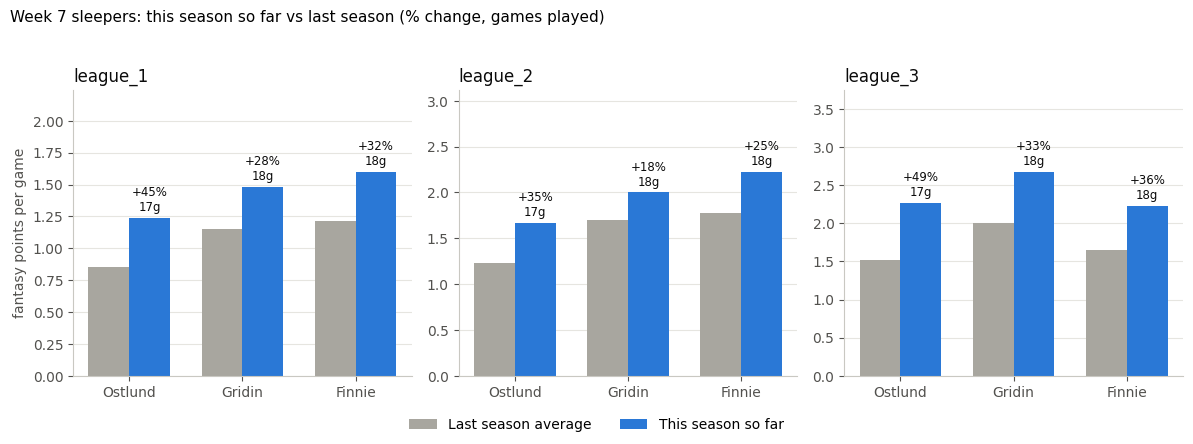

Loading game log for 8483500, 20262027 from cache, 0.0 hours old
Loading game log for 8483500, 20252026 from cache, 0.0 hours old
Loading game log for 8484860, 20262027 from cache, 0.0 hours old
Loading game log for 8484860, 20252026 from cache, 0.0 hours old
Loading game log for 8484471, 20262027 from cache, 0.0 hours old
Loading game log for 8484471, 20252026 from cache, 0.0 hours old


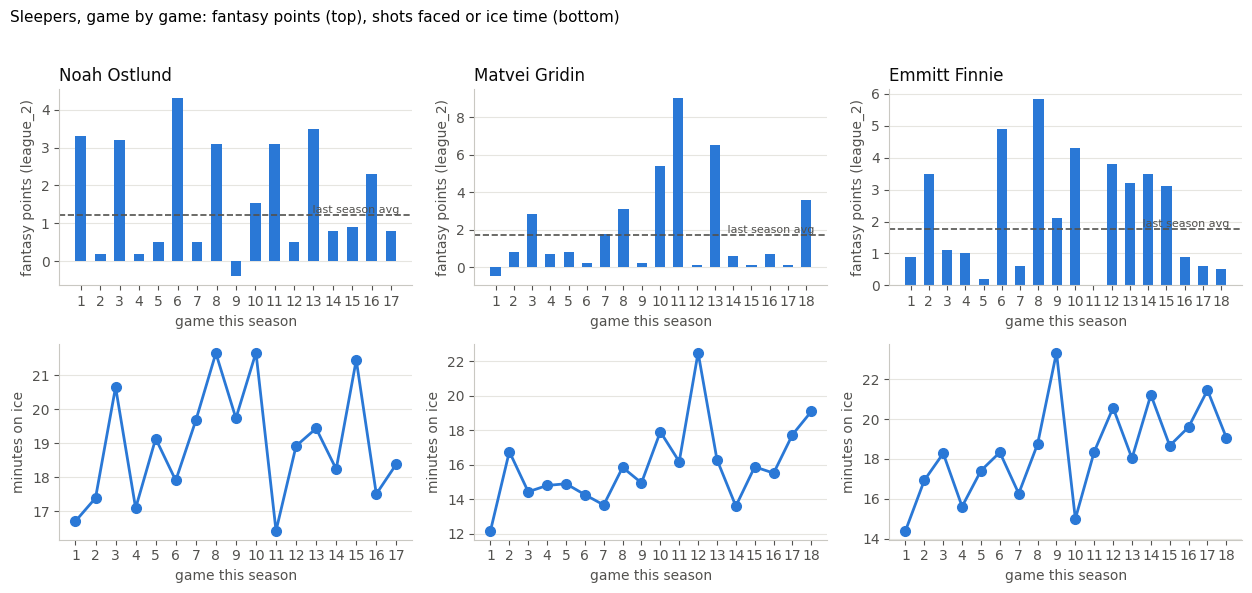

In [27]:
def plot_sleepers_w7(df):
    leagues = sorted(df["league"].unique())
    players = list(dict.fromkeys(df["player"]))
    fig, axes = plt.subplots(1, len(leagues), figsize=(4.0 * len(leagues), 4.4))
    axes = np.atleast_1d(axes)
    x = np.arange(len(players)); w = 0.36
    for ax, league in zip(axes, leagues):
        d = df[df["league"] == league].set_index("player").loc[players]
        ax.bar(x - w/2, d["last_season_avg"], w, color=GRAY, label="Last season average")
        ax.bar(x + w/2, d["this_season_avg"], w, color=BLUE, label="This season so far")
        top = np.nanmax([d["last_season_avg"].max(), d["this_season_avg"].max()])
        for xi, (_, r) in zip(x, d.iterrows()):
            if pd.isna(r["this_season_avg"]):
                continue
            lab = (f"{r['vs_last_season']:+.0%}\n{int(r['games'])}g" if pd.notna(r["vs_last_season"])
                   else f"{int(r['games'])}g\nno prior\nNHL games")
            ax.text(xi + w/2, r["this_season_avg"] + top * 0.02, lab, ha="center", va="bottom", fontsize=8.5, color=INK)
        ax.set_ylim(0, top * 1.4)
        ax.set_xticks(x); ax.set_xticklabels([p.split()[-1] for p in players])
        ax.set_title(league, loc="left"); ax.grid(axis="x", visible=False)
    axes[0].set_ylabel("fantasy points per game")
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=2, frameon=False)
    fig.suptitle("Week 7 sleepers: this season so far vs last season (% change, games played)", x=0.01, ha="left", fontsize=11)
    plt.tight_layout(rect=(0, 0.06, 1, 0.95)); plt.show()

plot_sleepers_w7(sleepers_w7)

def plot_sleeper_games_w7(league="league_2"):
    n = len(SLEEPERS_W7)
    fig, axes = plt.subplots(2, n, figsize=(4.2 * n, 6), squeeze=False)
    for j, name in enumerate(SLEEPERS_W7):
        pos = SLEEPER_POSITION_W7.get(name, "F")
        cfg, fmap = cfg_and_map(league, pos)
        pid = resolve_id(name)
        cur = _scored_game_log(pid, SEASON, pos, cfg, fmap, force_refresh=False)
        last_avg = get_prior_season_stats(pid, PRIOR_SEASON, pos, cfg, fmap)[0]
        ax, ax2 = axes[0, j], axes[1, j]
        if cur is None or cur.empty:
            ax.set_title(f"{name}: no games yet", loc="left"); continue
        cur = cur.reset_index(drop=True)
        g = np.arange(1, len(cur) + 1)
        ax.bar(g, cur["fantasy_points"], color=BLUE, width=0.55)
        if last_avg:
            ax.axhline(last_avg, color=MUTED, linestyle="--", linewidth=1.2)
            ax.text(g[-1] + 0.45, last_avg, " last season avg", color=MUTED, fontsize=8, va="bottom", ha="right")
        else:
            ax.text(0.98, 0.95, "no prior NHL games", transform=ax.transAxes, color=MUTED, fontsize=8, ha="right", va="top")
        ax.set_title(name, loc="left"); ax.set_xticks(g); ax.set_xlabel("game this season")
        ax.set_ylabel(f"fantasy points ({league})"); ax.grid(axis="x", visible=False)
        if pos == "G" and "shotsAgainst" in cur.columns:
            ax2.bar(g, pd.to_numeric(cur["shotsAgainst"], errors="coerce"), color=ORANGE, width=0.55)
            ax2.set_ylabel("shots against")
        elif "toi" in cur.columns:
            ax2.plot(g, cur["toi"].map(toi_minutes), color=BLUE, linewidth=2, marker="o", markersize=7)
            ax2.set_ylabel("minutes on ice")
        ax2.set_xticks(g); ax2.set_xlabel("game this season"); ax2.grid(axis="x", visible=False)
    fig.suptitle("Sleepers, game by game: fantasy points (top), shots faced or ice time (bottom)", x=0.01, ha="left", fontsize=11)
    plt.tight_layout(rect=(0, 0, 1, 0.96)); plt.show()

plot_sleeper_games_w7("league_2")

In [28]:
assert all(SLEEPER_THESIS_W7.values()), "write a thesis for every sleeper before saving"
sl_out = sleepers_w7.copy()
sl_out["week"] = 7
sl_out["thesis"] = sl_out["player"].map(SLEEPER_THESIS_W7)
sl_out["window_start"], sl_out["window_end"] = WEEK7["league_1"]
sl_out.to_csv("predictions/sleepers_week07.csv", index=False)
pd.concat([sleepers_process_w7.assign(kind="skater"), sleepers_goalie_w7.assign(kind="goalie")], ignore_index=True) \
  .to_csv("predictions/sleepers_week07_process.csv", index=False)
print("Saved sleepers_week07.csv and sleepers_week07_process.csv")
try:
    from google.colab import files  # type: ignore
    files.download("predictions/sleepers_week07.csv")
    files.download("predictions/sleepers_week07_process.csv")
except ImportError:
    pass

Saved sleepers_week07.csv and sleepers_week07_process.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Part 2: Week 5 Recap

Grading the Week 5 predictions (Wed Oct 28 to Sun Nov 1) against what happened. Needs `predictions/week05.csv`. This can wait until after the Week 7 games start.

In [29]:
w5 = pd.read_csv("predictions/week05.csv")
print(w5.shape)
print(w5["league"].value_counts().to_dict())
print(w5["prediction_unit"].dropna().unique(), int(w5["headline_pick"].sum()), "headline picks")
print("late_start:", w5["late_start"].dropna().unique(), "| window:", w5["window_start"].dropna().unique(), w5["window_end"].dropna().unique())

(45, 31)
{'league_3': 18, 'league_2': 14, 'league_1': 13}
['weekly_total'] 3 headline picks
late_start: [ True] | window: ['2026-10-28'] ['2026-11-01']


In [30]:
week5 = pd.read_csv("predictions/week05.csv")
week5_scored = week5[week5["p_me_outperforms"].notna()].copy()

rows = []
for _, r in week5_scored.iterrows():
    start, end = WEEK5[r["league"]]
    me = window_stats(r["me"], r["position"], r["league"], start, end)
    opp = window_stats(r["opponent"], r["position"], r["league"], start, end)
    rows.append({**r.to_dict(),
                 "me_games_actual": me["games"], "opp_games_actual": opp["games"],
                 "me_total": me["total"], "opp_total": opp["total"],
                 "result": outcome(me["total"], opp["total"])})

recap5 = pd.DataFrame(rows)
fav_me = recap5["favored"] == "me"
recap5["pick_won"] = np.where(fav_me, recap5["result"], 1 - recap5["result"])
recap5["brier"] = (recap5["p_me_outperforms"] - recap5["result"]) ** 2
recap5["confidence"] = np.maximum(recap5["p_me_outperforms"], 1 - recap5["p_me_outperforms"])

recap5.to_csv("predictions/week05_results.csv", index=False)
print(f"Scored {len(recap5)} Week 5 matchups")
print("Games predicted vs actual (mismatches):")
mm = recap5[(recap5["me_games"] != recap5["me_games_actual"]) | (recap5["opp_games"] != recap5["opp_games_actual"])]
print(mm[["league", "me", "opponent", "me_games", "me_games_actual", "opp_games", "opp_games_actual"]].to_string(index=False) if len(mm) else "none, all game counts matched")

Pulling fresh game log for 8478402, 20262027
Matched 'Morgan Geekie' to 'Morgan Geekie'
Pulling fresh game log for 8479987, 20262027
Pulling fresh game log for 8482116, 20262027
Matched 'Pavel Zacha' to 'Pavel Zacha'
Pulling fresh game log for 8478401, 20262027
Pulling fresh game log for 8476887, 20262027
Matched 'Jason Robertson' to 'Jason Robertson'
Pulling fresh game log for 8480027, 20262027
Pulling fresh game log for 8478398, 20262027
Matched 'Andrei Svechnikov' to 'Andrei Svechnikov'
Pulling fresh game log for 8480830, 20262027
Pulling fresh game log for 8482740, 20262027
Matched 'Jack Quinn' to 'Jack Quinn'
Pulling fresh game log for 8482097, 20262027
Pulling fresh game log for 8477949, 20262027
Matched 'Vasily Podkolzin' to 'Vasily Podkolzin'
Pulling fresh game log for 8481617, 20262027
Pulling fresh game log for 8479345, 20262027
Matched 'Shayne Gostisbehere' to 'Shayne Gostisbehere'
Pulling fresh game log for 8476906, 20262027
Pulling fresh game log for 8477346, 20262027
Matc

In [31]:
n = len(recap5)
print(f"Picks won: {recap5['pick_won'].sum():.1f} of {n} ({recap5['pick_won'].mean():.1%}), Brier {recap5['brier'].mean():.3f}")
print("Brier reference: 0.250 = always 50%.\n")

print("By league:")
print(recap5.groupby("league").agg(n=("pick_won","size"), won=("pick_won","sum"),
      hit_rate=("pick_won","mean"), brier=("brier","mean")).to_string(float_format=lambda v: f"{v:.3f}"))

recap5["bucket10"] = pd.cut(recap5["confidence"], [0.5,0.6,0.7,0.8,1.01], right=False,
                            labels=["50-60%","60-70%","70-80%","80%+"])
print("\nCalibration (10-point buckets):")
print(recap5.groupby("bucket10", observed=False).agg(n=("pick_won","size"), won=("pick_won","sum"),
      avg_conf=("confidence","mean"), hit_rate=("pick_won","mean")).to_string(float_format=lambda v: f"{v:.3f}"))

uneq_pred = recap5["me_games"] != recap5["opp_games"]
print("\nUnequal games (predicted):", f"{recap5[uneq_pred]['pick_won'].sum():.1f} of {uneq_pred.sum()}")
print("Equal games (predicted):  ", f"{recap5[~uneq_pred]['pick_won'].sum():.1f} of {(~uneq_pred).sum()}")

Picks won: 31.0 of 45 (68.9%), Brier 0.189
Brier reference: 0.250 = always 50%.

By league:
           n    won  hit_rate  brier
league                              
league_1  13  7.000     0.538  0.191
league_2  14 10.000     0.714  0.211
league_3  18 14.000     0.778  0.170

Calibration (10-point buckets):
           n    won  avg_conf  hit_rate
bucket10                               
50-60%    11  5.000     0.560     0.455
60-70%    11  6.000     0.653     0.545
70-80%    14 13.000     0.739     0.929
80%+       9  7.000     0.899     0.778

Unequal games (predicted): 16.0 of 19
Equal games (predicted):   15.0 of 26


In [32]:
cols = ["league","position","me","opponent","confidence","me_games_actual","opp_games_actual","me_total","opp_total","pick_won"]
print("Headline picks:")
hp = recap5[recap5["headline_pick"].astype(str).isin(["True", "1", "1.0", "2", "2.0", "3", "3.0"])]
print(hp.sort_values("league")[cols].to_string(index=False, float_format=lambda v: f"{v:.2f}"))

print("\nGoalie slots (expected games = team games x start share, vs actual appearances):")
g = recap5[recap5["position"] == "G"].copy()
g["me_exp"] = g["me_games"] * g["me_start_share"]
g["opp_exp"] = g["opp_games"] * g["opp_start_share"]
print(g[["league","me","me_exp","me_games_actual","opponent","opp_exp","opp_games_actual","me_total","opp_total","pick_won"]].to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print(f"\nAll goalies: {int(g['me_games_actual'].sum() + g['opp_games_actual'].sum())} appearances vs {g['me_exp'].sum() + g['opp_exp'].sum():.1f} expected")

print("\nBiggest misses (largest Brier):")
print(recap5.sort_values("brier", ascending=False).head(5)[["league","position","me","opponent","p_me_outperforms","me_total","opp_total","me_games_actual","opp_games_actual"]].to_string(index=False, float_format=lambda v: f"{v:.2f}"))

pts = pd.concat([
    recap5[["position","me","me_week_mu","me_total"]].set_axis(["position","player","pred","actual"], axis=1),
    recap5[["position","opponent","opp_week_mu","opp_total"]].set_axis(["position","player","pred","actual"], axis=1),
])
pts["err"] = pts["actual"] - pts["pred"]
print(f"\nMean expected {pts['pred'].mean():.2f}, mean actual {pts['actual'].mean():.2f}")
print(f"Correlation expected vs actual: {pts['pred'].corr(pts['actual']):.2f}")
print(pts.groupby(pts['position'].eq('G').map({True:'Goalies', False:'Skaters'}))["err"].agg(["size","mean"]).round(2))

Headline picks:
  league position             me         opponent  confidence  me_games_actual  opp_games_actual  me_total  opp_total  pick_won
league_1        C Connor McDavid    Morgan Geekie        0.95                3                 2      7.70       3.10      1.00
league_2        D Charlie McAvoy      Devon Toews        0.76                2                 2      6.00       7.65      0.00
league_3        C    Tim Stutzle Elias Pettersson        0.94                3                 2     16.25       1.00      1.00

Goalie slots (expected games = team games x start share, vs actual appearances):
  league                  me  me_exp  me_games_actual            opponent  opp_exp  opp_games_actual  me_total  opp_total  pick_won
league_1      Jeremy Swayman    1.32                1   Connor Hellebuyck     1.39                 1     -2.60       4.90      0.00
league_1      Jake Oettinger    1.32                2     Pyotr Kochetkov     1.00                 2      4.00      18.00     

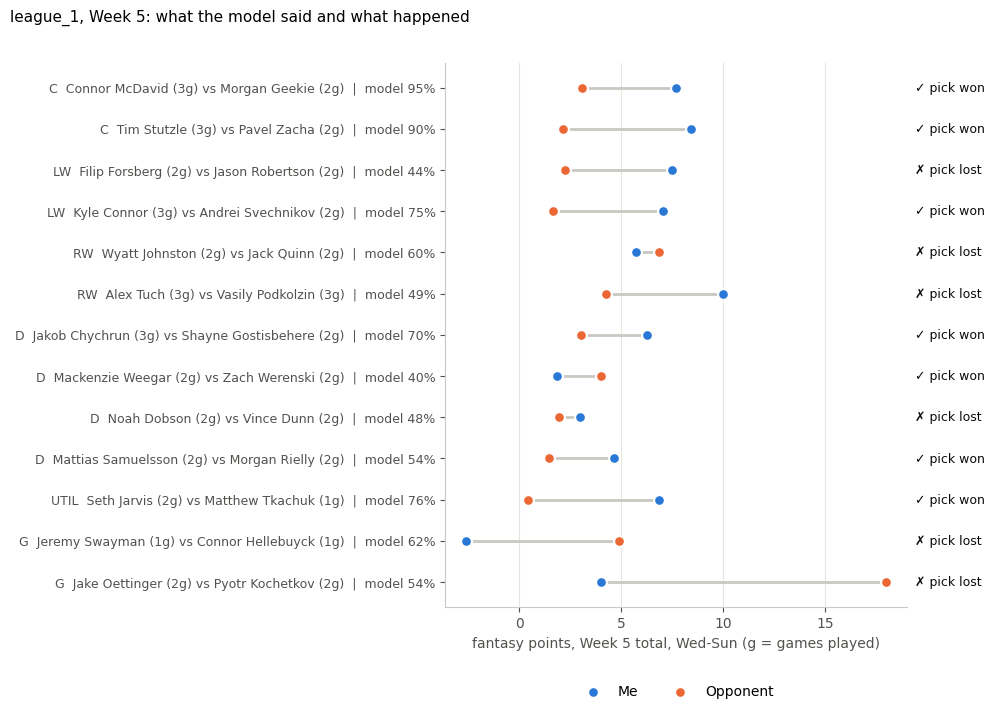

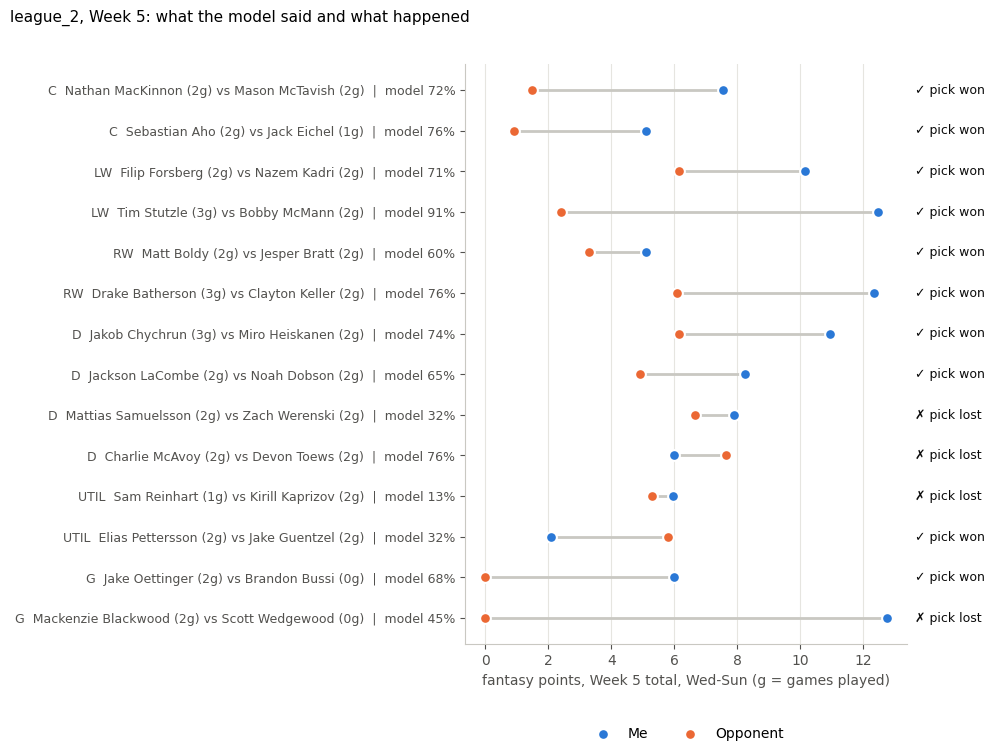

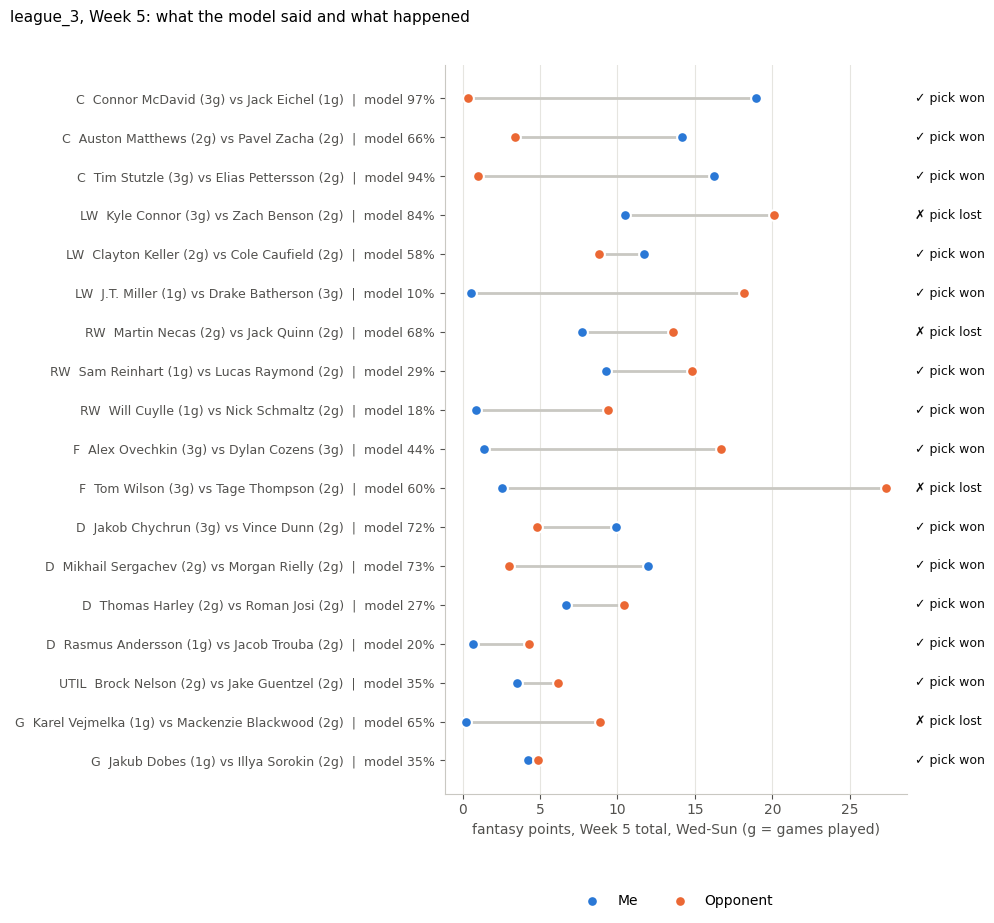

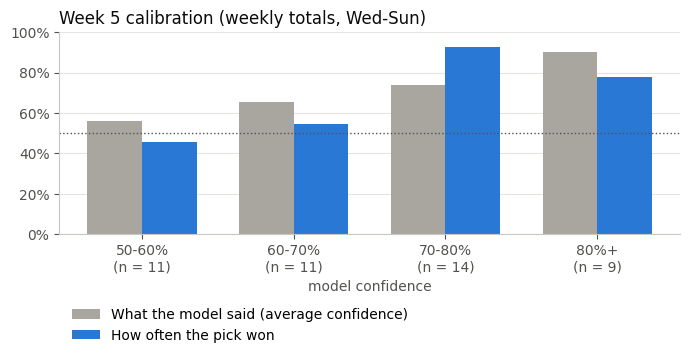

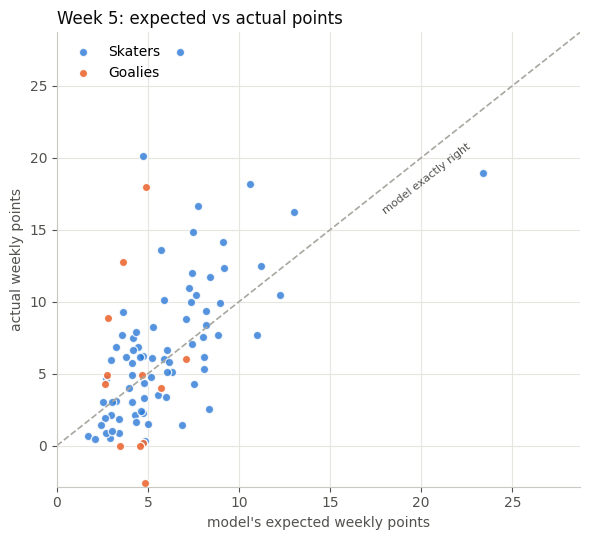

In [33]:
def plot_week5_matchups(league):
    d = recap5[recap5["league"] == league].reset_index(drop=True)
    y = np.arange(len(d))[::-1]
    fig, ax = plt.subplots(figsize=(10, 0.42 * len(d) + 1.8))
    for yi, r in zip(y, d.itertuples()):
        ax.plot([r.me_total, r.opp_total], [yi, yi], color="#c9c8c2", linewidth=2, zorder=1)
    ax.scatter(d["me_total"], y, s=60, color=BLUE, zorder=3, label="Me", edgecolor="white", linewidth=1.5)
    ax.scatter(d["opp_total"], y, s=60, color=ORANGE, zorder=3, label="Opponent", edgecolor="white", linewidth=1.5)
    labels = [f"{r.position}  {r.me} ({r.me_games_actual}g) vs {r.opponent} ({r.opp_games_actual}g)  |  model {r.p_me_outperforms:.0%}"
              for r in d.itertuples()]
    ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=9)
    right = ax.get_xlim()[1]
    for yi, r in zip(y, d.itertuples()):
        sym, txt = ("✓", "pick won") if r.pick_won == 1 else (("=", "tie") if r.pick_won == 0.5 else ("✗", "pick lost"))
        ax.text(right, yi, f"  {sym} {txt}", va="center", fontsize=9, color=INK, clip_on=False)
    ax.set_xlabel("fantasy points, Week 5 total, Wed-Sun (g = games played)")
    fig.suptitle(f"{league}, Week 5: what the model said and what happened", x=0.01, ha="left", fontsize=11)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False, ncol=2)
    ax.grid(axis="y", visible=False)
    plt.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

for lg in sorted(recap5["league"].unique()):
    plot_week5_matchups(lg)

cal = recap5.groupby("bucket10", observed=False).agg(n=("pick_won","size"),
      avg_conf=("confidence","mean"), hit=("pick_won","mean")).reset_index()
cal = cal[cal["n"] > 0]
x = np.arange(len(cal)); w = 0.36
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(x - w/2, cal["avg_conf"], w, color=GRAY, label="What the model said (average confidence)")
ax.bar(x + w/2, cal["hit"], w, color=BLUE, label="How often the pick won")
ax.axhline(0.5, color=MUTED, linewidth=1, linestyle=":")
ax.set_xticks(x); ax.set_xticklabels([f"{b}\n(n = {n})" for b, n in zip(cal["bucket10"].astype(str), cal["n"])])
ax.set_ylim(0, 1); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("model confidence"); ax.set_title("Week 5 calibration (weekly totals, Wed-Sun)", loc="left")
ax.legend(loc="upper left", frameon=False, bbox_to_anchor=(0, -0.3))
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6, 5.5))
sk, gl = pts[pts["position"] != "G"], pts[pts["position"] == "G"]
ax.scatter(sk["pred"], sk["actual"], s=36, color=BLUE, alpha=0.8, edgecolor="white", label="Skaters")
ax.scatter(gl["pred"], gl["actual"], s=36, color=ORANGE, alpha=0.9, edgecolor="white", label="Goalies")
lim = max(pts["pred"].max(), pts["actual"].max()) * 1.05
ax.plot([0, lim], [0, lim], color=GRAY, linewidth=1.2, linestyle="--")
ax.text(lim*0.62, lim*0.56, "model exactly right", color=MUTED, fontsize=8, rotation=38)
ax.set_xlim(0, lim); ax.set_ylim(min(0, pts["actual"].min()) * 1.1, lim)
ax.set_xlabel("model's expected weekly points"); ax.set_ylabel("actual weekly points")
ax.set_title("Week 5: expected vs actual points", loc="left")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

In [34]:
def scoreboard_block_w5():
    n, won = len(recap5), recap5["pick_won"].sum()
    eq = recap5["me_games"] == recap5["opp_games"]
    lines = [
        "**Week 5 results (weekly-total probabilities, Wed-Sun window)**", "",
        f"- All matchups: {won:.1f} of {n} picks won ({won/n:.1%}), Brier {recap5['brier'].mean():.3f}",
        f"- Unequal games: {recap5[~eq]['pick_won'].sum():.1f} of {(~eq).sum()}",
        f"- Equal games: {recap5[eq]['pick_won'].sum():.1f} of {eq.sum()}",
        "", "| Confidence | n | Won | Avg confidence | Hit rate |", "|---|---|---|---|---|",
    ]
    t = recap5.groupby("bucket10", observed=False).agg(n=("pick_won","size"), won=("pick_won","sum"),
            avg=("confidence","mean"), hit=("pick_won","mean"))
    for label, r in t.iterrows():
        if r["n"]:
            lines.append(f"| {label} | {int(r['n'])} | {r['won']:.0f} | {r['avg']:.1%} | {r['hit']:.1%} |")
    lines += ["", "Brier reference: 0.250 = always 50%."]
    return "\n".join(lines)

print(scoreboard_block_w5())

**Week 5 results (weekly-total probabilities, Wed-Sun window)**

- All matchups: 31.0 of 45 picks won (68.9%), Brier 0.189
- Unequal games: 16.0 of 19
- Equal games: 15.0 of 26

| Confidence | n | Won | Avg confidence | Hit rate |
|---|---|---|---|---|
| 50-60% | 11 | 5 | 56.0% | 45.5% |
| 60-70% | 11 | 6 | 65.3% | 54.5% |
| 70-80% | 14 | 13 | 73.9% | 92.9% |
| 80%+ | 9 | 7 | 89.9% | 77.8% |

Brier reference: 0.250 = always 50%.


In [35]:
# Running record across the weekly-total weeks (Weeks 2 to 5). Uses a local copy of each week's results if present, otherwise the repo.
import os
BASE = "https://raw.githubusercontent.com/avieno33/fantasy-hockey-weekly-predictions/main/predictions/"
parts = []
for wk in (2, 3, 4):
    name = f"week0{wk}_results.csv"
    local = f"predictions/{name}"
    try:
        df_wk = pd.read_csv(local) if os.path.exists(local) else pd.read_csv(BASE + name)
        parts.append(df_wk.assign(week=wk))
    except Exception as e:
        print(f"Week {wk} results not available yet, skipped:", e)
parts.append(recap5.assign(week=5))
both = pd.concat(parts, ignore_index=True)
both["bucket10"] = pd.cut(both["confidence"], [0.5, 0.6, 0.7, 0.8, 1.01], right=False, labels=["50-60%", "60-70%", "70-80%", "80%+"])
eqb = both["me_games"] == both["opp_games"]
print(f"Weeks {sorted(int(w) for w in both['week'].unique())}: {both['pick_won'].sum():.1f} of {len(both)} ({both['pick_won'].mean():.1%}), Brier {both['brier'].mean():.3f}")
print(f"  equal games:   {both[eqb]['pick_won'].sum():.1f} of {eqb.sum()}")
print(f"  unequal games: {both[~eqb]['pick_won'].sum():.1f} of {(~eqb).sum()}")
print(both.groupby("bucket10", observed=False).agg(n=("pick_won", "size"), won=("pick_won", "sum"), hit=("pick_won", "mean")).to_string(float_format=lambda v: f"{v:.3f}"))

Week 2 results not available yet, skipped: HTTP Error 404: Not Found
Week 3 results not available yet, skipped: HTTP Error 404: Not Found
Week 4 results not available yet, skipped: HTTP Error 404: Not Found
Weeks [5]: 31.0 of 45 (68.9%), Brier 0.189
  equal games:   15.0 of 26
  unequal games: 16.0 of 19
           n    won   hit
bucket10                 
50-60%    11  5.000 0.455
60-70%    11  6.000 0.545
70-80%    14 13.000 0.929
80%+       9  7.000 0.778


**What I take from Week 5:**

(Write after the outputs above. Compare against Week 4: the headline picks, the top-end confidence buckets (Week 4's 70%+ calls went 4 of 14), the equal-games record, and goalie appearances against start share.)

## Week 5 sleepers, did the thesis show up?

(Fill in after the outputs below. Kartye had only 1 team game, Washe and Shabanov 2.)

In [36]:
SEASON_START, PRE_WEEK_END = "2026-09-01", "2026-10-27"   # "before Week 5" = everything through Tuesday Oct 27

rows = []
for name in SLEEPERS_W5:
    pos = SLEEPER_POSITION.get(name, "F")
    pid = resolve_id(name)
    for league in ("league_1", "league_2", "league_3"):
        cfg, fmap = cfg_and_map(league, pos)
        w5 = window_stats(name, pos, league, *WEEK5[league])
        pre = window_stats(name, pos, league, SEASON_START, PRE_WEEK_END)
        w5_avg = w5["total"] / w5["games"] if w5["games"] else np.nan
        pre_avg = pre["total"] / pre["games"] if pre["games"] else np.nan
        last_avg, _ = get_prior_season_stats(pid, PRIOR_SEASON, pos, cfg, fmap)
        rows.append({"player": name, "league": league, "week5_games": w5["games"], "week5_avg": w5_avg,
                     "pre_week_avg": pre_avg, "last_season_avg": last_avg,
                     "vs_pre_week": (w5_avg / pre_avg - 1) if pre_avg and not pd.isna(w5_avg) else np.nan,
                     "vs_last_season": (w5_avg / last_avg - 1) if last_avg and not pd.isna(w5_avg) else np.nan})
sleepers_w5_recap = pd.DataFrame(rows)
print(sleepers_w5_recap.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

Loading game log for 8481789, 20262027 from cache, 0.1 hours old
Loading game log for 8481789, 20262027 from cache, 0.1 hours old
Loading game log for 8481789, 20252026 from cache, 0.1 hours old
Loading game log for 8481789, 20262027 from cache, 0.1 hours old
Loading game log for 8481789, 20262027 from cache, 0.1 hours old
Loading game log for 8481789, 20252026 from cache, 0.1 hours old
Loading game log for 8481789, 20262027 from cache, 0.1 hours old
Loading game log for 8481789, 20262027 from cache, 0.1 hours old
Loading game log for 8481789, 20252026 from cache, 0.1 hours old
Loading game log for 8485512, 20262027 from cache, 0.1 hours old
Loading game log for 8485512, 20262027 from cache, 0.1 hours old
Loading game log for 8485512, 20252026 from cache, 0.1 hours old
Loading game log for 8485512, 20262027 from cache, 0.1 hours old
Loading game log for 8485512, 20262027 from cache, 0.1 hours old
Loading game log for 8485512, 20252026 from cache, 0.1 hours old
Loading game log for 8485

In [37]:
periods = (("Before Week 5", SEASON, SEASON_START, PRE_WEEK_END),
           ("Week 5", SEASON, *WEEK5["league_1"]),
           ("Last season", PRIOR_SEASON, None, None))
skater_rows, goalie_rows = [], []
for name in SLEEPERS_W5:
    for label, season, s, e in periods:
        if SLEEPER_POSITION.get(name, "F") == "G":
            r = goalie_process(name, season, s, e)
            if r: goalie_rows.append({"player": name, "period": label, **r})
        else:
            r = process_window(name, season, s, e)
            if r: skater_rows.append({"player": name, "period": label, **r})

sleepers_process_w5r = pd.DataFrame(skater_rows)
sleepers_goalie_w5r = pd.DataFrame(goalie_rows)
print("Skaters:")
print(sleepers_process_w5r.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print("\nGoalie (start_share = starts / his team's games in that window):")
print(sleepers_goalie_w5r.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

Loading game log for 8481789, 20262027 from cache, 0.1 hours old
Loading game log for 8481789, 20262027 from cache, 0.1 hours old
Loading game log for 8481789, 20252026 from cache, 0.1 hours old
Loading game log for 8485512, 20262027 from cache, 0.1 hours old
Loading game log for 8485512, 20262027 from cache, 0.1 hours old
Loading game log for 8485512, 20252026 from cache, 0.1 hours old
Loading game log for 8485702, 20262027 from cache, 0.1 hours old
Loading game log for 8485702, 20262027 from cache, 0.1 hours old
Loading game log for 8485702, 20252026 from cache, 0.1 hours old
Skaters:
        player        period  games  pts_per_game  shots_per_game  shooting_pct  toi_per_game
    Tye Kartye Before Week 5     14          0.71            1.50          0.19         15.48
    Tye Kartye        Week 5      1          0.00            0.00           NaN         17.40
    Tye Kartye   Last season     64          0.34            0.88          0.14         11.96
     Tim Washe Before Week 5  

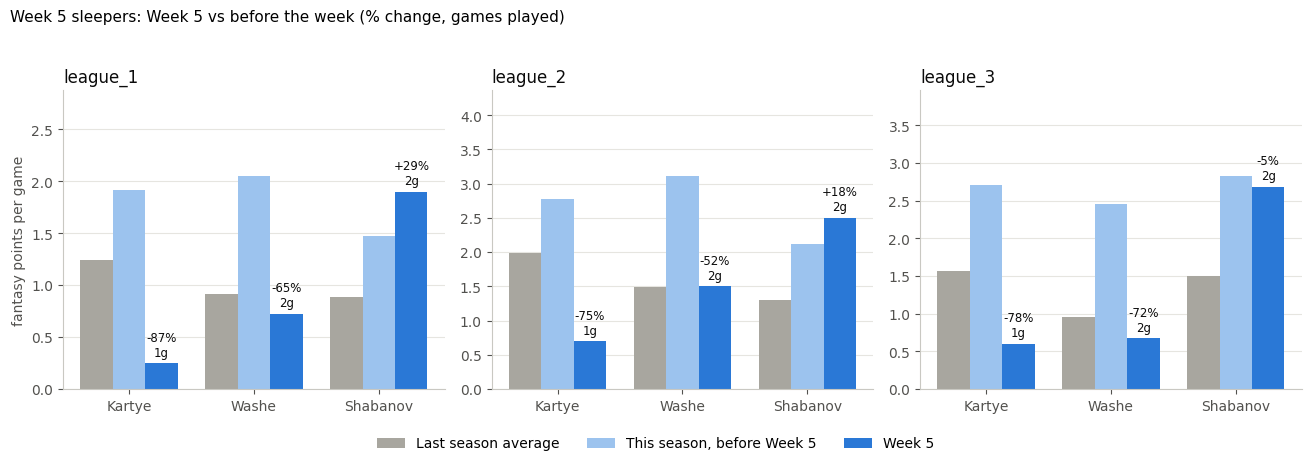

Loading game log for 8481789, 20262027 from cache, 0.1 hours old
Loading game log for 8485512, 20262027 from cache, 0.1 hours old
Loading game log for 8485702, 20262027 from cache, 0.1 hours old


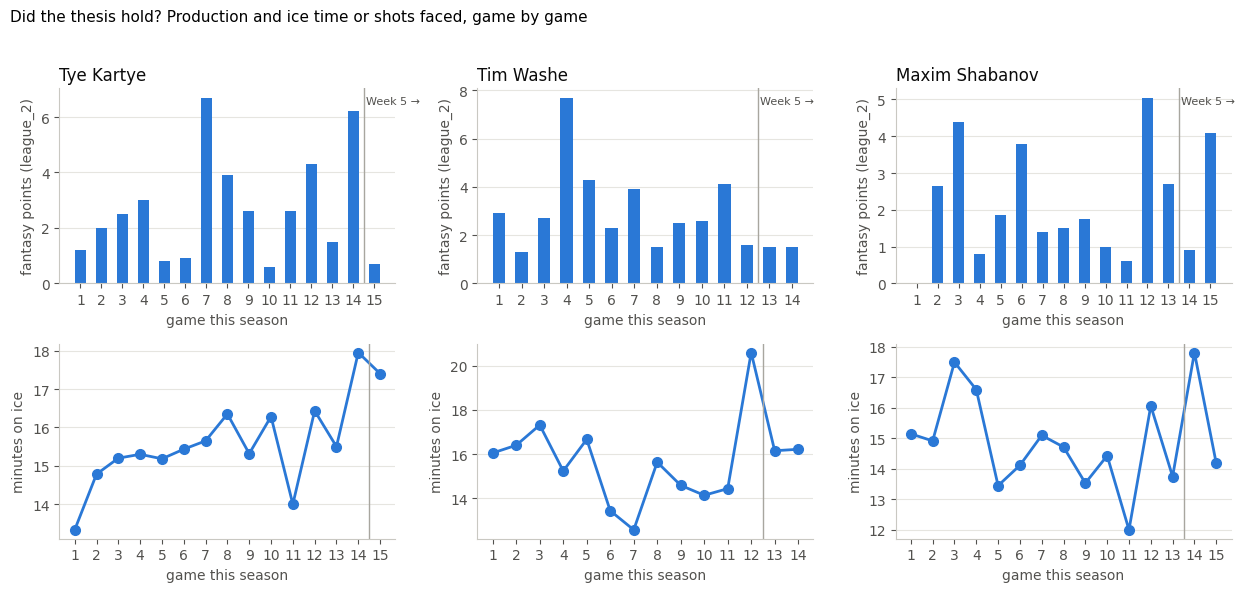

In [38]:
LIGHT = "#9cc3ee"

def plot_sleeper_recap_w5(df):
    leagues = sorted(df["league"].unique())
    players = list(dict.fromkeys(df["player"]))
    fig, axes = plt.subplots(1, len(leagues), figsize=(4.4 * len(leagues), 4.6))
    axes = np.atleast_1d(axes)
    x = np.arange(len(players)); w = 0.26
    for ax, league in zip(axes, leagues):
        d = df[df["league"] == league].set_index("player").loc[players]
        ax.bar(x - w, d["last_season_avg"], w, color=GRAY, label="Last season average")
        ax.bar(x, d["pre_week_avg"], w, color=LIGHT, label="This season, before Week 5")
        ax.bar(x + w, d["week5_avg"], w, color=BLUE, label="Week 5")
        top = np.nanmax(d[["last_season_avg", "pre_week_avg", "week5_avg"]].values)
        for xi, (_, r) in zip(x, d.iterrows()):
            if pd.notna(r["week5_avg"]):
                lab = f"{r['vs_pre_week']:+.0%}\n{int(r['week5_games'])}g" if pd.notna(r["vs_pre_week"]) else f"{int(r['week5_games'])}g"
                ax.text(xi + w, r["week5_avg"] + top * 0.02, lab, ha="center", va="bottom", fontsize=8.5, color=INK)
        ax.set_ylim(0, top * 1.4)
        ax.set_xticks(x); ax.set_xticklabels([p.split()[-1] for p in players])
        ax.set_title(league, loc="left"); ax.grid(axis="x", visible=False)
    axes[0].set_ylabel("fantasy points per game")
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=3, frameon=False)
    fig.suptitle("Week 5 sleepers: Week 5 vs before the week (% change, games played)", x=0.01, ha="left", fontsize=11)
    plt.tight_layout(rect=(0, 0.07, 1, 0.95)); plt.show()

plot_sleeper_recap_w5(sleepers_w5_recap)

def plot_sleeper_games_w5r(league="league_2"):
    n = len(SLEEPERS_W5)
    fig, axes = plt.subplots(2, n, figsize=(4.2 * n, 6), squeeze=False)
    for j, name in enumerate(SLEEPERS_W5):
        pos = SLEEPER_POSITION.get(name, "F")
        cfg, fmap = cfg_and_map(league, pos)
        pid = resolve_id(name)
        cur = _scored_game_log(pid, SEASON, pos, cfg, fmap, force_refresh=False)
        ax, ax2 = axes[0, j], axes[1, j]
        if cur is None or cur.empty:
            ax.set_title(f"{name}: no games yet", loc="left"); continue
        cur = cur[cur["gameDate"] <= pd.Timestamp(WEEK5["league_1"][1])].reset_index(drop=True)
        g = np.arange(1, len(cur) + 1)
        split = int((cur["gameDate"] < pd.Timestamp(WEEK5["league_1"][0])).sum()) + 0.5
        ax.bar(g, cur["fantasy_points"], color=BLUE, width=0.55)
        ax.axvline(split, color=GRAY, linewidth=1)
        ax.text(split + 0.1, ax.get_ylim()[1] * 0.92, "Week 5 →", color=MUTED, fontsize=8)
        ax.set_title(name, loc="left"); ax.set_xticks(g); ax.set_xlabel("game this season")
        ax.set_ylabel(f"fantasy points ({league})"); ax.grid(axis="x", visible=False)
        if pos == "G" and "shotsAgainst" in cur.columns:
            ax2.bar(g, pd.to_numeric(cur["shotsAgainst"], errors="coerce"), color=ORANGE, width=0.55)
            ax2.set_ylabel("shots against")
        elif "toi" in cur.columns:
            ax2.plot(g, cur["toi"].map(toi_minutes), color=BLUE, linewidth=2, marker="o", markersize=7)
            ax2.set_ylabel("minutes on ice")
        ax2.axvline(split, color=GRAY, linewidth=1)
        ax2.set_xticks(g); ax2.set_xlabel("game this season"); ax2.grid(axis="x", visible=False)
    fig.suptitle("Did the thesis hold? Production and ice time or shots faced, game by game", x=0.01, ha="left", fontsize=11)
    plt.tight_layout(rect=(0, 0, 1, 0.96)); plt.show()

plot_sleeper_games_w5r("league_2")

In [39]:
sleepers_w5_recap.to_csv("predictions/sleepers_week05_results.csv", index=False)
print("Saved predictions/sleepers_week05_results.csv")

Saved predictions/sleepers_week05_results.csv


## To do on the weekend (clean-up)

- [ ] Write the Week 7 analysis text and the sleeper table, and note the headline picks.
- [ ] Write "What I take from Week 5" and the Week 5 sleeper recap.
- [ ] Push `week04_results.csv`, `week05_results.csv`, `sleepers_week04_results.csv` and `sleepers_week05_results.csv`, and `week02_results.csv` / `week03_results.csv` if they still aren't on main. Then re-run the running-record cell.
- [ ] Update `SCOREBOARD.md`: Weeks 4 and 5 results, Week 6 as "missed, no predictions", and the Week 7 predictions.
- [ ] The model review planned for Monday Nov 9 didn't happen. Pick a new date. Model v1 is still in use and has not been changed.